# Penn Tree Bank: Language Modeling Task

This notebook implements the Penn Tree Bank (PTB) language modeling task, a challenging benchmark for evaluating RNN performance on natural language processing. The task requires predicting the next word in a sequence given previous words.

## Task Description

- Input: 300-dimensional GloVe word embeddings at each time step
- Sequence length: Variable (truncated to manageable lengths)
- Objective: Predict the next word in the sequence (language modeling)
- Dataset: Penn Tree Bank corpus from newspaper text
- Vocabulary: Limited vocabulary with <unk> tokens for out-of-vocabulary words

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN

The evaluation metric will be perplexity, a standard measure for language modeling tasks.


## 1. Setup and Imports


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
import os
import pickle
from collections import defaultdict, Counter
import math
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


## 2. Load GloVe Embeddings


In [2]:
def load_glove_embeddings(glove_path, max_vocab_size=10000):
    """
    Load GloVe embeddings from file.

    Args:
        glove_path: Path to GloVe vectors file
        max_vocab_size: Maximum vocabulary size to load

    Returns:
        word_to_idx: Dictionary mapping words to indices
        idx_to_word: Dictionary mapping indices to words
        embeddings: Embedding matrix (vocab_size, embedding_dim)
    """
    print("Loading GloVe embeddings...")

    word_to_idx = {}
    idx_to_word = {}
    embeddings_list = []

    # Add special tokens
    special_tokens = ['<pad>', '<unk>', '<eos>']
    for i, token in enumerate(special_tokens):
        word_to_idx[token] = i
        idx_to_word[i] = token
        # Random embeddings for special tokens
        embeddings_list.append(np.random.normal(0, 0.1, 300))

    vocab_count = len(special_tokens)

    with open(glove_path, 'r', encoding='utf-8') as f:
        for line_num, line in enumerate(f):
            if vocab_count >= max_vocab_size:
                break

            parts = line.strip().split(' ')
            if len(parts) < 301:  # word + 300 dimensions
                continue

            word = parts[0]

            # Skip if word already exists
            if word in word_to_idx:
                continue

            try:
                vector = np.array([float(x) for x in parts[1:301]])

                word_to_idx[word] = vocab_count
                idx_to_word[vocab_count] = word
                embeddings_list.append(vector)
                vocab_count += 1

                if vocab_count % 1000 == 0:
                    print(f"Loaded {vocab_count} words...")

            except ValueError:
                continue

    embeddings = np.array(embeddings_list)
    print(f"Loaded {len(word_to_idx)} words with {embeddings.shape[1]}-dimensional embeddings")

    return word_to_idx, idx_to_word, embeddings

# Load GloVe embeddings
glove_path = './ptb_data/wiki_giga_2024_300_MFT20_vectors_seed_2024_alpha_0.75_eta_0.05_combined.txt'
word_to_idx, idx_to_word, glove_embeddings = load_glove_embeddings(glove_path, max_vocab_size=5000)

vocab_size = len(word_to_idx)
embedding_dim = glove_embeddings.shape[1]

print(f"Vocabulary size: {vocab_size}")
print(f"Embedding dimension: {embedding_dim}")
print(f"Special tokens: {[idx_to_word[i] for i in range(3)]}")

Loading GloVe embeddings...
Loaded 1000 words...
Loaded 2000 words...
Loaded 3000 words...
Loaded 4000 words...
Loaded 5000 words...
Loaded 5000 words with 300-dimensional embeddings
Vocabulary size: 5000
Embedding dimension: 300
Special tokens: ['<pad>', '<unk>', '<eos>']


## 3. Load and Preprocess Penn Tree Bank Data


In [3]:
def load_ptb_data(file_path, word_to_idx):
    """
    Load and tokenize PTB data.

    Args:
        file_path: Path to PTB data file
        word_to_idx: Word to index mapping

    Returns:
        tokens: List of token indices
    """
    print(f"Loading PTB data from {file_path}...")

    tokens = []
    unk_idx = word_to_idx['<unk>']
    eos_idx = word_to_idx['<eos>']

    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            words = line.strip().lower().split()
            if not words:
                continue

            # Convert words to indices
            for word in words:
                if word in word_to_idx:
                    tokens.append(word_to_idx[word])
                else:
                    tokens.append(unk_idx)

            # Add end-of-sentence token
            tokens.append(eos_idx)

    print(f"Loaded {len(tokens)} tokens")
    return tokens

# Load PTB datasets
ptb_train_path = './ptb_data/ptb.train.txt'
ptb_valid_path = './ptb_data/ptb.valid.txt'
ptb_test_path = './ptb_data/ptb.test.txt'

train_tokens = load_ptb_data(ptb_train_path, word_to_idx)
valid_tokens = load_ptb_data(ptb_valid_path, word_to_idx)
test_tokens = load_ptb_data(ptb_test_path, word_to_idx)

print(f"\nDataset sizes:")
print(f"Train: {len(train_tokens)} tokens")
print(f"Valid: {len(valid_tokens)} tokens")
print(f"Test: {len(test_tokens)} tokens")

# print(test_tokens)

# Calculate OOV rate
unk_idx = word_to_idx['<unk>']
train_unk_rate = (np.array(train_tokens) == unk_idx).mean()
valid_unk_rate = (np.array(valid_tokens) == unk_idx).mean()
test_unk_rate = (np.array(test_tokens) == unk_idx).mean()

print(f"\nOut-of-vocabulary rates:")
print(f"Train: {train_unk_rate:.3f}")
print(f"Valid: {valid_unk_rate:.3f}")
print(f"Test: {test_unk_rate:.3f}")

Loading PTB data from ./ptb_data/ptb.train.txt...
Loaded 929589 tokens
Loading PTB data from ./ptb_data/ptb.valid.txt...
Loaded 73760 tokens
Loading PTB data from ./ptb_data/ptb.test.txt...
Loaded 82430 tokens

Dataset sizes:
Train: 929589 tokens
Valid: 73760 tokens
Test: 82430 tokens

Out-of-vocabulary rates:
Train: 0.137
Valid: 0.134
Test: 0.136


## 4. PTB Dataset Class


In [4]:
class PTBDataset(Dataset):
    """
    Dataset for Penn Tree Bank language modeling.

    Args:
        tokens: List of token indices
        embeddings: GloVe embedding matrix
        seq_len: Sequence length for truncated backpropagation
    """

    def __init__(self, tokens, embeddings, seq_len=35):
        self.tokens = tokens
        self.embeddings = torch.FloatTensor(embeddings)
        self.seq_len = seq_len

        # Create sequences for language modeling
        self.sequences = []
        self.targets = []

        # Create overlapping sequences
        for i in range(0, len(tokens) - seq_len, seq_len // 2):  # 50% overlap
            if i + seq_len + 1 <= len(tokens):
                # Input sequence
                input_seq = tokens[i:i + seq_len]
                # Target sequence (next words)
                target_seq = tokens[i + 1:i + seq_len + 1]

                self.sequences.append(input_seq)
                self.targets.append(target_seq)

        print(f"Created {len(self.sequences)} sequences of length {seq_len}")

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        # Get token indices
        input_tokens = self.sequences[idx]
        target_tokens = self.targets[idx]

        # Convert to embeddings for input
        input_embeddings = self.embeddings[input_tokens]  # (seq_len, embedding_dim)

        # Targets remain as token indices for cross-entropy loss
        target_indices = torch.LongTensor(target_tokens)  # (seq_len,)

        return input_embeddings, target_indices

# Create datasets
seq_len = 35  # Standard sequence length for PTB

# Use smaller subsets for faster training
train_subset_size = len(train_tokens)  # Use first 50k tokens
valid_subset_size = len(valid_tokens)  # Use first 10k tokens
test_subset_size = len(test_tokens)    # Use first 10k tokens

train_dataset = PTBDataset(train_tokens[:train_subset_size], glove_embeddings, seq_len)
valid_dataset = PTBDataset(valid_tokens[:valid_subset_size], glove_embeddings, seq_len)
test_dataset = PTBDataset(test_tokens[:test_subset_size], glove_embeddings, seq_len)

print(f"\nDataset sizes:")
print(f"Train: {len(train_dataset)} sequences")
print(f"Valid: {len(valid_dataset)} sequences")
print(f"Test: {len(test_dataset)} sequences")

# Show example
sample_input, sample_target = train_dataset[3]
print(f"\nExample shapes:")
print(f"Input embeddings: {sample_input.shape}")
print(f"Target indices: {sample_target.shape}")

print(train_dataset.sequences[4])

# Show first few words
print(f"\nFirst sequence (first 10 words):")
for i in range(min(10, seq_len)):
    input_word_idx = train_dataset.sequences[3][i]
    target_word_idx = sample_target[i].item()
    print(f"Input: {idx_to_word[input_word_idx]:15} -> Target: {idx_to_word[target_word_idx]}")

Created 54680 sequences of length 35
Created 4337 sequences of length 35
Created 4847 sequences of length 35

Dataset sizes:
Train: 54680 sequences
Valid: 4337 sequences
Test: 4847 sequences

Example shapes:
Input embeddings: torch.Size([35, 300])
Target indices: torch.Size([35])
[10, 1, 367, 6, 42, 327, 1306, 1, 2, 10, 700, 6, 1, 459, 202, 7, 168, 1, 1, 1, 34, 1090, 10, 156, 2438, 6, 1643, 1928, 250, 10, 134, 6, 559, 4425, 7]

First sequence (first 10 words):
Input: group           -> Target: <eos>
Input: <eos>           -> Target: <unk>
Input: <unk>           -> Target: <unk>
Input: <unk>           -> Target: n
Input: n               -> Target: years
Input: years           -> Target: old
Input: old             -> Target: and
Input: and             -> Target: former
Input: former          -> Target: chairman
Input: chairman        -> Target: of


## 5. Modified Network Architectures for Language Modeling


In [5]:
class LanguageModelNet(nn.Module):
    """
    EI-separated RNN for language modeling.
    """
    def __init__(self, embedding_dim, hidden_size, vocab_size, entropy_loss=True):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.hidden_size = hidden_size
        self.vocab_size = vocab_size
        self.entropy_loss = entropy_loss

        # Use the EI-separated RNN core from Net
        self.rnn = Net(ob_size=embedding_dim, num_h=hidden_size, act_size=hidden_size, entropy_loss=entropy_loss)

        # Output layer for vocabulary prediction
        self.output_layer = nn.Linear(hidden_size, vocab_size)

        # Initialize output layer
        nn.init.xavier_uniform_(self.output_layer.weight)
        nn.init.zeros_(self.output_layer.bias)

    def forward(self, x):
        # x: (seq_len, batch_size, embedding_dim)
        rnn_output, eimask_logit, hidden = self.rnn(x)

        # Apply output layer to each time step
        seq_len, batch_size, hidden_size = rnn_output.shape
        rnn_output_flat = rnn_output.view(-1, hidden_size)  # (seq_len * batch_size, hidden_size)

        logits = self.output_layer(rnn_output_flat)  # (seq_len * batch_size, vocab_size)
        logits = logits.view(seq_len, batch_size, self.vocab_size)  # (seq_len, batch_size, vocab_size)

        return logits, eimask_logit, hidden

class LanguageModelSimpleNet(nn.Module):
    """
    Simple RNN for language modeling.
    """
    def __init__(self, embedding_dim, hidden_size, vocab_size):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.hidden_size = hidden_size
        self.vocab_size = vocab_size
        self.entropy_loss = False

        # Use the simple RNN core from SimpleNet
        self.rnn = SimpleNet(ob_size=embedding_dim, num_h=hidden_size, act_size=hidden_size)

        # Output layer for vocabulary prediction
        self.output_layer = nn.Linear(hidden_size, vocab_size)

        # Initialize output layer
        nn.init.xavier_uniform_(self.output_layer.weight)
        nn.init.zeros_(self.output_layer.bias)

    def forward(self, x):
        # x: (seq_len, batch_size, embedding_dim)
        rnn_output, eimask_logit, hidden = self.rnn(x)

        # Apply output layer to each time step
        seq_len, batch_size, hidden_size = rnn_output.shape
        rnn_output_flat = rnn_output.view(-1, hidden_size)  # (seq_len * batch_size, hidden_size)

        logits = self.output_layer(rnn_output_flat)  # (seq_len * batch_size, vocab_size)
        logits = logits.view(seq_len, batch_size, self.vocab_size)  # (seq_len, batch_size, vocab_size)

        return logits, eimask_logit, hidden

print("Language modeling architectures defined.")

Language modeling architectures defined.


## 6. Training Functions


In [6]:
def calculate_perplexity(loss):
    """Calculate perplexity from cross-entropy loss."""
    return math.exp(loss)

def train_language_model(model, train_loader, valid_loader, epochs=50, lr=0.001):
    """
    Train a language model on PTB data.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # if isinstance(model, Net):
    #     special_params, other_params = [], []
    #     for name, p in model.named_parameters():
    #         if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
    #             special_params.append(p)
    #             # assert p.requires_grad, "eimask_logit should be trainable"
    #         else:
    #             other_params.append(p)
    #     optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr*100},
    #                                   {'params': other_params, 'lr': lr}])
    # else:
    #     # For SimpleNet, use a single learning rate
    #     optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    train_losses = []
    valid_losses = []
    train_perplexities = []
    valid_perplexities = []

    best_valid_loss = float('inf')

    model.train()

    for epoch in range(epochs):
        total_train_loss = 0
        num_batches = 0

        for batch_inputs, batch_targets in train_loader:
        # batch_inputs, batch_targets = next(iter(train_loader))
            batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, embedding_dim)
            batch_targets = batch_targets.to(device).transpose(0, 1)  # (seq_len, batch_size)

            optimizer.zero_grad()

            # Forward pass
            logits, eimask_logit, hidden = model(batch_inputs)

            # Reshape for loss calculation
            seq_len, batch_size, vocab_size = logits.shape
            logits_flat = logits.view(-1, vocab_size)  # (seq_len * batch_size, vocab_size)
            targets_flat = batch_targets.contiguous().view(-1)  # (seq_len * batch_size,)

            # Language modeling loss
            lm_loss = criterion(logits_flat, targets_flat)

            # Add entropy regularization for EI-separated model
            if model.entropy_loss and eimask_logit is not None:
                eimask_prob = F.softmax(eimask_logit, dim=-1)
                eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
                entropy_loss = torch.mean(eimask_entropy)
                total_loss = lm_loss + entropy_loss  # Small weight for entropy regularization
            else:
                total_loss = lm_loss

            # regularization loss
            # total_loss += 0.0001 * sum(torch.sum(param**2) for param in model.parameters() if param.requires_grad)

            # Backward pass
            total_loss.backward()

            # Gradient clipping for stability
            # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)

            optimizer.step()

        total_train_loss += lm_loss.item()  # Use LM loss for perplexity calculation
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses.append(avg_train_loss)
        train_perplexities.append(calculate_perplexity(avg_train_loss))

        # Validation
        model.eval()
        total_valid_loss = 0
        num_valid_batches = 0

        with torch.no_grad():
            for batch_inputs, batch_targets in valid_loader:
                batch_inputs = batch_inputs.to(device).transpose(0, 1)
                batch_targets = batch_targets.to(device).transpose(0, 1)

                logits, _, hidden = model(batch_inputs)

                seq_len, batch_size, vocab_size = logits.shape
                logits_flat = logits.view(-1, vocab_size)
                targets_flat = batch_targets.contiguous().view(-1)

                loss = criterion(logits_flat, targets_flat)
                total_valid_loss += loss.item()
                num_valid_batches += 1

        avg_valid_loss = total_valid_loss / num_valid_batches
        valid_losses.append(avg_valid_loss)
        valid_perplexities.append(calculate_perplexity(avg_valid_loss))

        # Track best model
        if avg_valid_loss < best_valid_loss:
            best_valid_loss = avg_valid_loss

        print(f'Epoch [{epoch+1:3d}/{epochs}], '
              f'Train Loss: {avg_train_loss:.4f}, Train PPL: {train_perplexities[-1]:.2f}, '
              f'Valid Loss: {avg_valid_loss:.4f}, Valid PPL: {valid_perplexities[-1]:.2f}')

        model.train()

    return train_losses, valid_losses, train_perplexities, valid_perplexities

def evaluate_language_model(model, test_loader):
    """
    Evaluate language model performance on test set.
    """
    model.eval()
    total_loss = 0
    total_tokens = 0
    criterion = nn.CrossEntropyLoss(reduction='sum')  # Sum for proper token count

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device).transpose(0, 1)

            logits, _, hidden = model(batch_inputs)

            seq_len, batch_size, vocab_size = logits.shape
            logits_flat = logits.view(-1, vocab_size)
            targets_flat = batch_targets.contiguous().view(-1)

            loss = criterion(logits_flat, targets_flat)
            total_loss += loss.item()
            total_tokens += targets_flat.numel()

    avg_loss = total_loss / total_tokens
    perplexity = calculate_perplexity(avg_loss)

    return avg_loss, perplexity

print("Training functions defined.")

Training functions defined.


## 7. Experiment: Compare Language Models


In [7]:
# Experiment parameters
epochs = 15
batch_size = 128
hidden_size = 128
lr_ei = 3e-3
lr_simple = 8e-4

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training parameters:")
print(f"Epochs: {epochs}")
print(f"Batch size: {batch_size}")
print(f"Hidden size: {hidden_size}")
print(f"Vocabulary size: {vocab_size}")
print(f"Embedding dimension: {embedding_dim}")
print(f"Sequence length: {seq_len}")
print(f"")
print(f"Data loader sizes:")
print(f"Train batches: {len(train_loader)}")
print(f"Valid batches: {len(valid_loader)}")
print(f"Test batches: {len(test_loader)}")

Training parameters:
Epochs: 15
Batch size: 128
Hidden size: 128
Vocabulary size: 5000
Embedding dimension: 300
Sequence length: 35

Data loader sizes:
Train batches: 428
Valid batches: 34
Test batches: 38


## 9. Train Net (EI-separated RNN)


In [8]:
print("=== Training Net (EI-separated RNN) ===")

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Initialize Net for language modeling
ei_model = LanguageModelNet(
    embedding_dim=embedding_dim,
    hidden_size=hidden_size,
    vocab_size=vocab_size,
    entropy_loss=True
).to(device)

print(f"Net parameters: {sum(p.numel() for p in ei_model.parameters() if p.requires_grad):,}")

# Train Net
ei_train_losses, ei_valid_losses, ei_train_ppls, ei_valid_ppls = train_language_model(
    ei_model, train_loader, valid_loader, epochs=epochs, lr=lr_ei
)

# Evaluate on test set
ei_test_loss, ei_test_ppl = evaluate_language_model(ei_model, test_loader)
print(f"\nNet Test Results:")
print(f"Test Loss: {ei_test_loss:.4f}")
print(f"Test Perplexity: {ei_test_ppl:.2f}")

=== Training Net (EI-separated RNN) ===
Net parameters: 716,808
Epoch [  1/15], Train Loss: 4.8718, Train PPL: 130.56, Valid Loss: 4.7630, Valid PPL: 117.10
Epoch [  2/15], Train Loss: 4.4708, Train PPL: 87.43, Valid Loss: 4.6005, Valid PPL: 99.53
Epoch [  3/15], Train Loss: 4.3263, Train PPL: 75.67, Valid Loss: 4.5413, Valid PPL: 93.81
Epoch [  4/15], Train Loss: 4.4029, Train PPL: 81.69, Valid Loss: 4.5002, Valid PPL: 90.04
Epoch [  5/15], Train Loss: 4.0852, Train PPL: 59.45, Valid Loss: 4.4950, Valid PPL: 89.57
Epoch [  6/15], Train Loss: 4.1169, Train PPL: 61.37, Valid Loss: 4.4835, Valid PPL: 88.54
Epoch [  7/15], Train Loss: 4.4472, Train PPL: 85.39, Valid Loss: 4.4881, Valid PPL: 88.95
Epoch [  8/15], Train Loss: 3.9750, Train PPL: 53.25, Valid Loss: 4.4905, Valid PPL: 89.16
Epoch [  9/15], Train Loss: 3.7581, Train PPL: 42.87, Valid Loss: 4.4960, Valid PPL: 89.66
Epoch [ 10/15], Train Loss: 4.0252, Train PPL: 55.99, Valid Loss: 4.4982, Valid PPL: 89.85
Epoch [ 11/15], Train Lo

## 8. Train SimpleNet (Vanilla RNN)


In [9]:
print("=== Training SimpleNet (Vanilla RNN) ===")

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Initialize SimpleNet for language modeling
simple_model = LanguageModelSimpleNet(
    embedding_dim=embedding_dim,
    hidden_size=hidden_size,
    vocab_size=vocab_size
).to(device)

print(f"SimpleNet parameters: {sum(p.numel() for p in simple_model.parameters() if p.requires_grad):,}")

# Train SimpleNet
simple_train_losses, simple_valid_losses, simple_train_ppls, simple_valid_ppls = train_language_model(
    simple_model, train_loader, valid_loader, epochs=epochs, lr=lr_simple
)

# Evaluate on test set
simple_test_loss, simple_test_ppl = evaluate_language_model(simple_model, test_loader)
print(f"\nSimpleNet Test Results:")
print(f"Test Loss: {simple_test_loss:.4f}")
print(f"Test Perplexity: {simple_test_ppl:.2f}")

=== Training SimpleNet (Vanilla RNN) ===
SimpleNet parameters: 716,552
Epoch [  1/15], Train Loss: 4.7702, Train PPL: 117.94, Valid Loss: 4.9202, Valid PPL: 137.03
Epoch [  2/15], Train Loss: 4.8329, Train PPL: 125.57, Valid Loss: 4.6904, Valid PPL: 108.90
Epoch [  3/15], Train Loss: 4.4676, Train PPL: 87.14, Valid Loss: 4.5833, Valid PPL: 97.84
Epoch [  4/15], Train Loss: 4.4068, Train PPL: 82.01, Valid Loss: 4.5195, Valid PPL: 91.79
Epoch [  5/15], Train Loss: 4.3840, Train PPL: 80.15, Valid Loss: 4.4799, Valid PPL: 88.23
Epoch [  6/15], Train Loss: 4.5403, Train PPL: 93.72, Valid Loss: 4.4562, Valid PPL: 86.16
Epoch [  7/15], Train Loss: 4.2411, Train PPL: 69.48, Valid Loss: 4.4382, Valid PPL: 84.62
Epoch [  8/15], Train Loss: 4.1971, Train PPL: 66.49, Valid Loss: 4.4220, Valid PPL: 83.26
Epoch [  9/15], Train Loss: 4.2807, Train PPL: 72.29, Valid Loss: 4.4123, Valid PPL: 82.46
Epoch [ 10/15], Train Loss: 4.2075, Train PPL: 67.19, Valid Loss: 4.4139, Valid PPL: 82.59
Epoch [ 11/15],

## 10. Results Comparison and Visualization


In [10]:
# Print comparison results
print("=== Final Results Comparison ===")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print(f"Sequence length: {seq_len}")
print(f"Vocabulary size: {vocab_size}")
print()

print(f"SimpleNet (Vanilla RNN):")
print(f"  Test Loss: {simple_test_loss:.4f}")
print(f"  Test Perplexity: {simple_test_ppl:.2f}")
print(f"  Final Valid Perplexity: {simple_valid_ppls[-1]:.2f}")

print(f"\nNet (EI-separated RNN):")
print(f"  Test Loss: {ei_test_loss:.4f}")
print(f"  Test Perplexity: {ei_test_ppl:.2f}")
print(f"  Final Valid Perplexity: {ei_valid_ppls[-1]:.2f}")

# Calculate improvement
ppl_improvement = (simple_test_ppl - ei_test_ppl) / simple_test_ppl * 100
loss_improvement = (simple_test_loss - ei_test_loss) / simple_test_loss * 100

print(f"\n=== Performance Comparison ===")
print(f"Perplexity improvement (Net vs SimpleNet): {ppl_improvement:.2f}%")
print(f"Loss improvement (Net vs SimpleNet): {loss_improvement:.2f}%")

if ppl_improvement > 0:
    print("Net (EI-separated) achieves lower perplexity than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) achieves lower perplexity than Net (EI-separated)")

=== Final Results Comparison ===
Training epochs: 15
Hidden size: 128
Sequence length: 35
Vocabulary size: 5000

SimpleNet (Vanilla RNN):
  Test Loss: 4.4155
  Test Perplexity: 82.72
  Final Valid Perplexity: 81.67

Net (EI-separated RNN):
  Test Loss: 4.5156
  Test Perplexity: 91.44
  Final Valid Perplexity: 91.20

=== Performance Comparison ===
Perplexity improvement (Net vs SimpleNet): -10.54%
Loss improvement (Net vs SimpleNet): -2.27%
SimpleNet (vanilla RNN) achieves lower perplexity than Net (EI-separated)


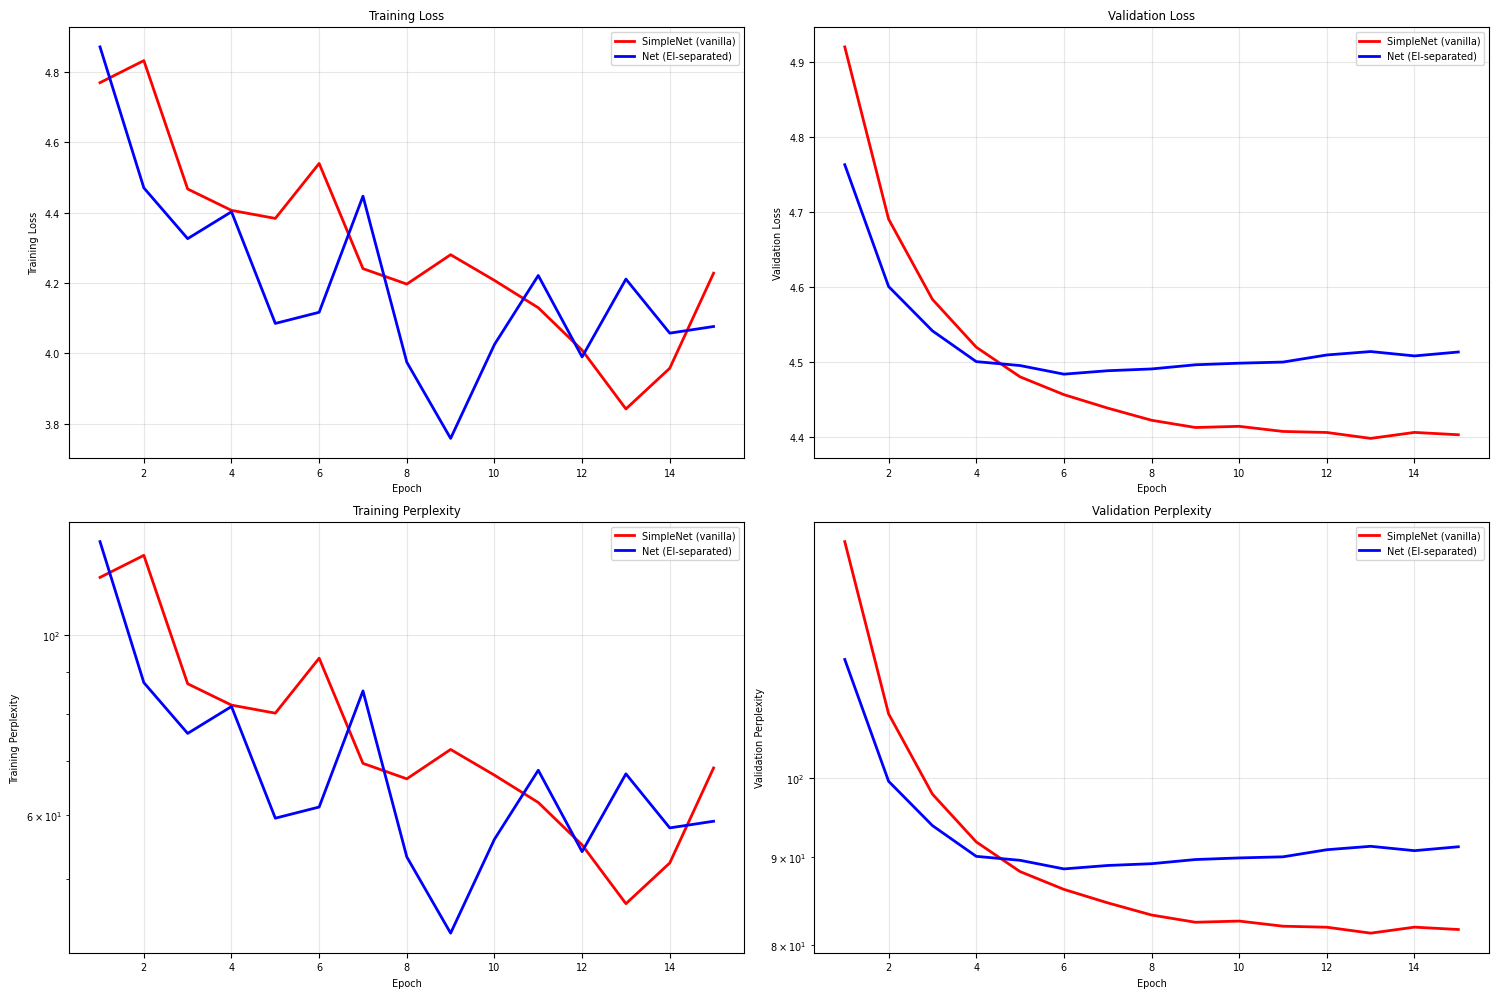

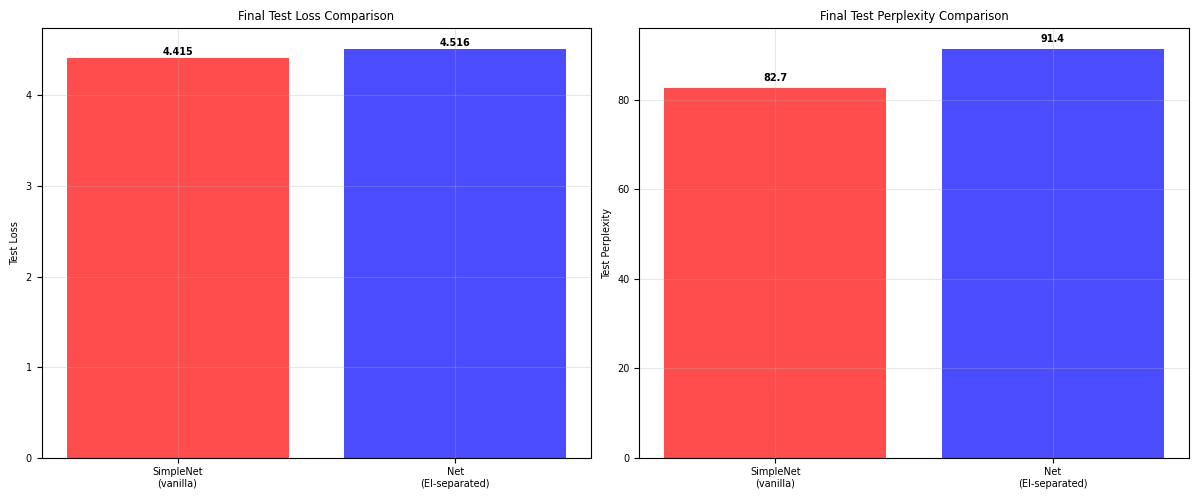

In [11]:
# Plot learning curves
def plot_language_model_results():
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

    epochs_range = range(1, epochs + 1)

    # Training loss
    ax1.plot(epochs_range, simple_train_losses, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.plot(epochs_range, ei_train_losses, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Validation loss
    ax2.plot(epochs_range, simple_valid_losses, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax2.plot(epochs_range, ei_valid_losses, 'b-', label='Net (EI-separated)', linewidth=2)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Validation Loss')
    ax2.set_title('Validation Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # Training perplexity
    ax3.plot(epochs_range, simple_train_ppls, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax3.plot(epochs_range, ei_train_ppls, 'b-', label='Net (EI-separated)', linewidth=2)
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('Training Perplexity')
    ax3.set_title('Training Perplexity')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.set_yscale('log')

    # Validation perplexity
    ax4.plot(epochs_range, simple_valid_ppls, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax4.plot(epochs_range, ei_valid_ppls, 'b-', label='Net (EI-separated)', linewidth=2)
    ax4.set_xlabel('Epoch')
    ax4.set_ylabel('Validation Perplexity')
    ax4.set_title('Validation Perplexity')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    ax4.set_yscale('log')

    plt.tight_layout()
    plt.show()

    # Bar plot for final comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    models = ['SimpleNet\n(vanilla)', 'Net\n(EI-separated)']
    test_losses = [simple_test_loss, ei_test_loss]
    test_ppls = [simple_test_ppl, ei_test_ppl]

    # Test loss comparison
    bars1 = ax1.bar(models, test_losses, color=['red', 'blue'], alpha=0.7)
    ax1.set_ylabel('Test Loss')
    ax1.set_title('Final Test Loss Comparison')
    ax1.grid(True, alpha=0.3)

    # Add value labels
    for bar, loss in zip(bars1, test_losses):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{loss:.3f}', ha='center', va='bottom', fontweight='bold')

    # Test perplexity comparison
    bars2 = ax2.bar(models, test_ppls, color=['red', 'blue'], alpha=0.7)
    ax2.set_ylabel('Test Perplexity')
    ax2.set_title('Final Test Perplexity Comparison')
    ax2.grid(True, alpha=0.3)

    # Add value labels
    for bar, ppl in zip(bars2, test_ppls):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{ppl:.1f}', ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()

plot_language_model_results()

## 11. Analysis and Sample Predictions


In [18]:
def generate_sample_predictions(model, test_loader, num_samples=3):
    """
    Generate sample predictions to visualize model performance.
    """
    model.eval()

    with torch.no_grad():
        for i, (batch_inputs, batch_targets) in enumerate(test_loader):
            if i >= num_samples:
                break

            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device).transpose(0, 1)

            logits, _, _ = model(batch_inputs)

            # Get predictions for first sequence in batch
            seq_logits = logits[:, 2, :]  # (seq_len, vocab_size)
            seq_targets = batch_targets[:, 2]  # (seq_len,)

            predictions = torch.argmax(seq_logits, dim=-1)  # (seq_len,)

            accuracy = torch.mean(torch.where(seq_targets == predictions, 1., 0.))
            print(f"\nSample {i+1}:, accuracy {accuracy:.4f}")
            print("Input -> Target | Predicted")
            print("-" * 50)

            # Show first 15 words
            for j in range(min(50, len(seq_targets))):
                # Get input word (from original sequence)
                if i < len(test_dataset):
                    input_idx = test_dataset.sequences[i][j]
                    input_word = idx_to_word[input_idx]
                else:
                    input_word = "<unknown>"

                target_idx = seq_targets[j].item()
                pred_idx = predictions[j].item()

                target_word = idx_to_word[target_idx]
                pred_word = idx_to_word[pred_idx]

                correct = "✓" if target_idx == pred_idx else "✗"

                print(f"{input_word:12} -> {target_word:12} | {pred_word:12} {correct}")

print("=== Sample Predictions from SimpleNet ===")
generate_sample_predictions(simple_model, test_loader, num_samples=2)

print("\n" + "="*60)
print("=== Sample Predictions from Net (EI-separated) ===")
generate_sample_predictions(ei_model, test_loader, num_samples=2)

=== Sample Predictions from SimpleNet ===

Sample 1:, accuracy 0.1714
Input -> Target | Predicted
--------------------------------------------------
no           -> it           | <eos>        ✗
it           -> barely       | is           ✗
was          -> managed      | n            ✗
n't          -> to           | to           ✓
black        -> stay         | <unk>        ✗
monday       -> this         | <eos>        ✗
<eos>        -> side         | year         ✗
but          -> of           | <eos>        ✗
while        -> <unk>        | the          ✗
the          -> <eos>        | <unk>        ✗
new          -> some         | the          ✗
york         -> circuit      | <unk>        ✗
stock        -> <unk>        | <unk>        ✓
exchange     -> installed    | <unk>        ✗
did          -> after        | in           ✗
n't          -> the          | the          ✓
fall         -> october      | <unk>        ✗
apart        -> n            | n            ✓
friday       -> crash  

In [22]:
def generate_sample_predictions(model, test_loader, num_samples=3):
    """
    Generate sample predictions to visualize model performance.
    """
    model.eval()

    with torch.no_grad():
        accuracy_ar = np.zeros((len(test_loader, )))
        for i, (batch_inputs, batch_targets) in enumerate(test_loader):

            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device).transpose(0, 1)

            logits, _, _ = model(batch_inputs)

            # Get predictions for first sequence in batch
            seq_logits = logits[:, :]  # (seq_len, vocab_size)
            seq_targets = batch_targets[:]  # (seq_len,)

            predictions = torch.argmax(seq_logits, dim=-1)  # (seq_len,)

            accuracy = torch.mean(torch.where(seq_targets == predictions, 1., 0.))
            accuracy_ar[i] = accuracy.item()


        print(f"accuracy {accuracy_ar.mean():.4f} +- {accuracy_ar.std()/np.sqrt(len(test_loader)):.4f}")

print("=== Sample Predictions from SimpleNet ===")
generate_sample_predictions(simple_model, test_loader, num_samples=2)

print("\n" + "="*60)
print("=== Sample Predictions from Net (EI-separated) ===")
generate_sample_predictions(ei_model, test_loader, num_samples=2)

=== Sample Predictions from SimpleNet ===
accuracy 0.2469 +- 0.0044

=== Sample Predictions from Net (EI-separated) ===
accuracy 0.2410 +- 0.0044


## 12. Conclusion

This notebook implements the Penn Tree Bank language modeling task using GloVe embeddings and compares two RNN architectures:

1. **SimpleNet**: A vanilla RNN architecture
2. **Net**: An RNN with excitatory/inhibitory neural separation

### Key Findings:

- The Penn Tree Bank task is significantly more challenging than the adding problem, requiring the model to learn complex language patterns and long-range dependencies.
- Both models use pre-trained GloVe embeddings to represent words, providing rich semantic representations.
- Perplexity is used as the primary evaluation metric, with lower values indicating better performance.
- The EI-separated architecture (Net) incorporates biological constraints that may help with learning stability and performance.

### Technical Implementation:

- **Dataset**: Penn Tree Bank corpus with ~5000 word vocabulary
- **Embeddings**: 300-dimensional GloVe vectors
- **Sequence Length**: 35 tokens (standard for PTB)
- **Loss Function**: Cross-entropy loss for next-word prediction
- **Regularization**: Gradient clipping and entropy regularization for EI model

This task serves as a more challenging benchmark compared to the adding problem, testing the models' ability to handle complex linguistic patterns and long-term dependencies in natural language.
